In [1]:
%load_ext autoreload
%autoreload 2
import jax.numpy as jnp
import jax_sn
import jax
import matplotlib.pyplot as plt
import numpy as onp
import equinox as eqx
jax.config.update("jax_enable_x64", True)
from functools import partial
import pyvista as pv

import lineax as lx
from jax_sn.operators.multi_group_operator import MultiGroupLowerTriangularBlockSolver, MultiGroupOperatorScanCheckpoint
from jax_sn.solution_domain import SolutionDomainData, SolutionDomain, BasixLagrangianSimplex
from typing import Tuple, Callable, Iterable
from dataclasses import dataclass
from breeding_blanket_setup import _get_bb_args, _setup_bb_mgop_symmetric, aux_data_dict, bb_data_dict
import mcbb

In [2]:
hcpb_blanket = mcbb.examples.hcpb()
n_samples_per_batch =1e4
groups_list = [14.1e6, 1e6, 300, 10, 0]
n_x_tally = 200
settings = mcbb.blanket_base.OpenMCSettingsBlanket(True, "openmc_data/", 10, n_samples_per_batch )
simulation_symm = mcbb.linear_blanket.OpenMCSymmetricLinearBlanketSimulation(hcpb_blanket, settings, n_x_tally, groups_list)
mgxs_lib, tally_result = simulation_symm.create_mgxs_library(onp.flip(groups_list), 4)
openmc_data = mcbb.openmc_base_functions.mgxs_lib_to_data_dicts(mgxs_lib)

/home/tbogaarts/miniconda3/envs/jaxsbgeom/lib/python3.12/site-packages/openmc/mixin.py:70: IDWarning: Another Filter instance already exists with id=1.
  warn(msg, IDWarning)
/home/tbogaarts/miniconda3/envs/jaxsbgeom/lib/python3.12/site-packages/openmc/mixin.py:70: IDWarning: Another Filter instance already exists with id=410.
  warn(msg, IDWarning)
/home/tbogaarts/miniconda3/envs/jaxsbgeom/lib/python3.12/site-packages/openmc/mixin.py:70: IDWarning: Another Filter instance already exists with id=13.
  warn(msg, IDWarning)


In [12]:
from mcbb.sn.base_sn import setup_linear_symm_mgop
from jax_sn.operators.multi_group_operator.right_hand_side import IsotropicSourceSingleGroup, solve_multigroup_operator_rhs, TotalSource
from jax_sn.operators.multi_group_operator import MultiGroupLowerTriangularBlockSolver, AdjointMultiGroupOperatorScan, MultiGroupOperator
from jax_sn.operators.transport_operator.transport_operator_base import TransportOperatorVmapPallas
from jax_sn.operators.multi_group_operator import RightHandSide
from jax_sn.variance_reduction import fw_cadis_scalar_flux

degree = 3
mgop, source_int =setup_linear_symm_mgop(hcpb_blanket, openmc_data[0], [10 for i in range(8)], degree, 3, single_angle_transport_operator_cls = TransportOperatorVmapPallas)
element = BasixLagrangianSimplex(degree, 1)

solution_domain = SolutionDomain.from_element_and_domain(element, mgop.domain)

solver    = lx.BiCGStab(1e-10, 1e-10, max_steps=200)

In [17]:
importance_map = fw_cadis_scalar_flux(mgop, IsotropicSourceSingleGroup.from_operator(mgop,source_int,0), solver)

In [49]:
from mcbb.openmc_base_functions import _importance_map_to_weight_windows

In [23]:
onp.sum([layer.thickness for layer in hcpb_blanket.layers])

np.float64(2.232)

In [64]:
from mcbb.sn.base_sn import create_weight_windows_for_blanket
d, importance_map = create_weight_windows_for_blanket(hcpb_blanket, openmc_data[0], [10 for i in range(8)], degree, 3, n_weight_windows_in_blanket=20, single_angle_transport_operator_cls = TransportOperatorVmapPallas)

In [65]:
ww_up, ww_down = _importance_map_to_weight_windows(importance_map)

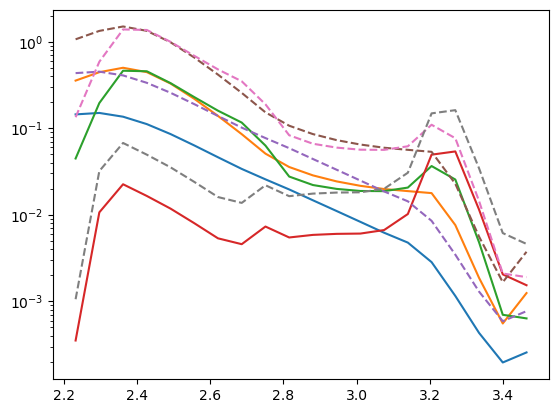

In [66]:
plt.semilogy(d, ww_up.T)
plt.semilogy(d, ww_down.T,'--')

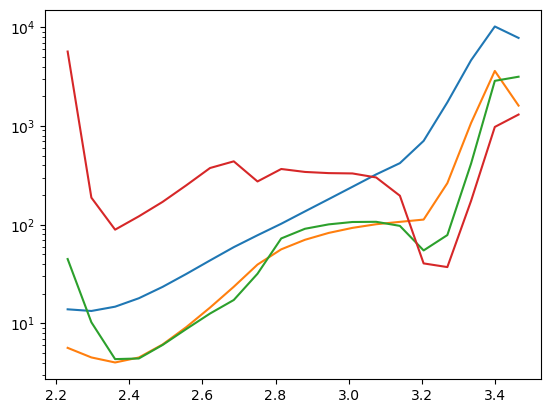

In [47]:
plt.semilogy(d, importance_map.T)

In [48]:
x = jnp.linspace(0,3.5)[:, None]
plt.semilogy(x, solution_domain.interpolate(x, importance_map[:, 0]).T)

AssertionError: Solution must be of shape ShapeDtypeStruct(shape=(150, 4), dtype=float64) but got (4,)